In [2]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/jshanky
/kaggle/input/datasets/jshanky/zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset/images
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset/images


In [3]:
import os
import shutil
import pandas as pd

# Original dataset paths
train_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset'
test_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset'

# Label files
train_excel = os.path.join(train_source, 'class_label.xlsx')
test_csv = os.path.join(test_source, 'class label.csv')

# Image folders
train_images = os.path.join(train_source, 'images')
test_images = os.path.join(test_source, 'images')

# New folders for ImageFolder
output_root = '/kaggle/working/PCOSGen-train'

train_dir = os.path.join(output_root, 'train')
test_dir = os.path.join(output_root, 'test')

# Create class folders
for directory in [
    os.path.join(train_dir, 'Appears normal'),
    os.path.join(train_dir, 'Appears abnormal'),
    os.path.join(test_dir, 'Appears normal'),
    os.path.join(test_dir, 'Appears abnormal')
]:
    os.makedirs(directory, exist_ok=True)

# Read labels
train_df = pd.read_excel(train_excel)
test_df = pd.read_csv(test_csv)

# Column we actually want
label_column = 'Class label (whether the ultrasound images appears normal or has some abnormality)'

# Function to copy images according to labels
def prepare_dataset(df, image_source, output_dir):
    copied = 0
    skipped = 0

    for _, row in df.iterrows():

        image_path = str(row['imagePath']).strip()
        label = str(row[label_column]).strip().lower()

        # Ignore Unknown / missing labels
        if label == 'unknown' or label == 'nan':
            skipped += 1
            continue

        # Determine target class
        if 'normal' in label and 'abnormal' not in label:
            class_name = 'Appears normal'
        elif 'abnormal' in label:
            class_name = 'Appears abnormal'
        else:
            skipped += 1
            continue

        # ImagePath may contain directories, so use only the filename
        image_name = os.path.basename(image_path)
        source_file = os.path.join(image_source, image_name)

        if not os.path.exists(source_file):
            skipped += 1
            continue

        destination = os.path.join(output_dir, class_name, image_name)

        shutil.copy2(source_file, destination)
        copied += 1

    return copied, skipped


# Prepare train and test
train_copied, train_skipped = prepare_dataset(
    train_df,
    train_images,
    train_dir
)

test_copied, test_skipped = prepare_dataset(
    test_df,
    test_images,
    test_dir
)

print("Dataset preparation complete!")
print(f"Train images copied : {train_copied}")
print(f"Train images skipped: {train_skipped}")
print(f"Test images copied  : {test_copied}")
print(f"Test images skipped : {test_skipped}")

Dataset preparation complete!
Train images copied : 3200
Train images skipped: 1
Test images copied  : 1468
Test images skipped : 0


In [4]:
from collections import Counter
import os

for split in ['train', 'test']:
    print(f"\n{split.upper()}")

    for class_name in ['Appears normal', 'Appears abnormal']:
        path = os.path.join(output_root, split, class_name)
        count = len(os.listdir(path))
        print(f"{class_name}: {count}")


TRAIN
Appears normal: 903
Appears abnormal: 2297

TEST
Appears normal: 416
Appears abnormal: 1052


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 220MB/s]
100%|██████████| 43/43 [00:19<00:00,  2.21it/s]


Epoch [1/50] Train Loss: 0.4769 (CE: 0.5899, Dice: 0.3638), Train Acc: 0.6695 | Val Loss: 0.4837 (CE: 0.6107, Dice: 0.3567), Val Acc: 0.6750
  -> Saving best model (Val Accuracy: 0.6750)


100%|██████████| 43/43 [00:17<00:00,  2.45it/s]


...

Epoch [9/50] Train Loss: 0.4060 (CE: 0.4832, Dice: 0.3287), Train Acc: 0.7140 | Val Loss: 0.4866 (CE: 0.6142, Dice: 0.3589), Val Acc: 0.6604
  -> No improvement for 7/8 epochs


100%|██████████| 43/43 [00:18<00:00,  2.37it/s]


Epoch [10/50] Train Loss: 0.4052 (CE: 0.4912, Dice: 0.3192), Train Acc: 0.7243 | Val Loss: 0.5315 (CE: 0.6840, Dice: 0.3791), Val Acc: 0.5833
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 10. Best Val Accuracy: 0.6958


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)



Final Test Loss: 0.4218 (CE: 0.3215, Dice: 0.5221), Final Test Accuracy: 0.9121

Test Precision (weighted): 0.9137
Test Recall (weighted):    0.9121
Test F1-score (weighted):  0.9088

Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.91      0.98      0.94      1052
  Appears normal       0.93      0.74      0.83       416

        accuracy                           0.91      1468
       macro avg       0.92      0.86      0.88      1468
    weighted avg       0.91      0.91      0.91      1468



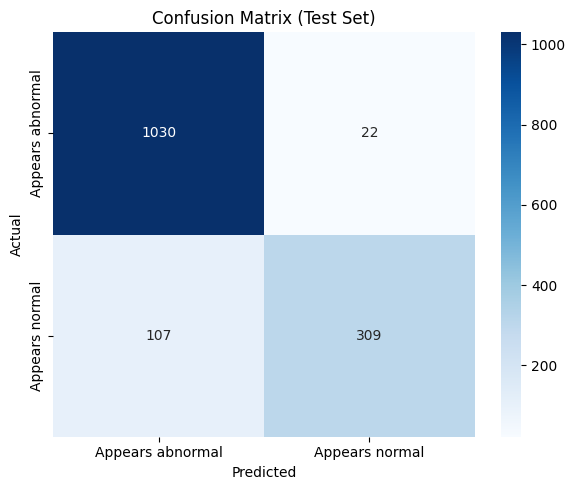

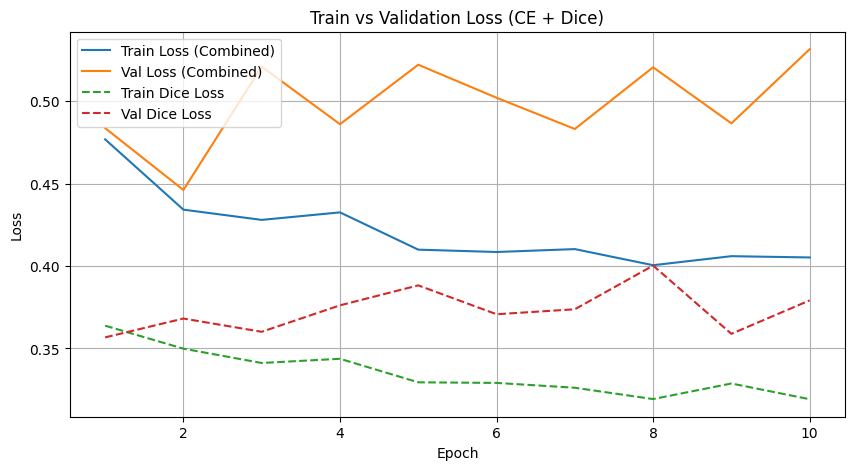

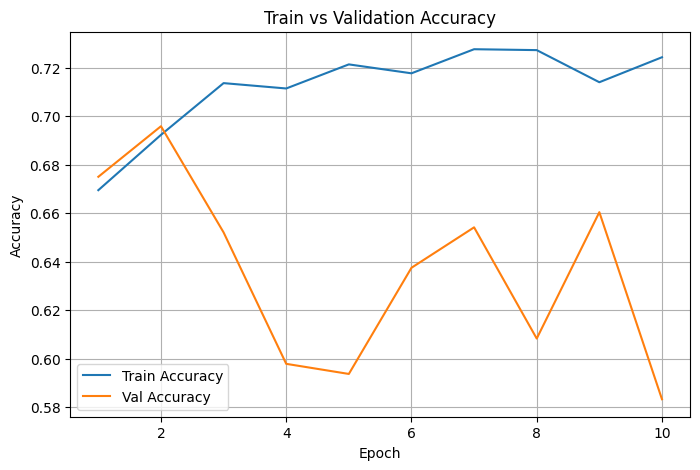


Summary:
Best Val Accuracy during training: 0.6958
Final Test Accuracy (evaluated once, held-out set): 0.9121
Final Test Precision: 0.9137, Recall: 0.9121, F1-score: 0.9088
Final Test Dice Loss: 0.5221


In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, transforms, models
from tqdm import tqdm
import numpy as np
import os
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report
import seaborn as sns

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Paths to train and test datasets
train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'

# Image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Datasets
train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=test_transform)

# Split train_dataset into train_subset + val_subset (85/15)
val_size = int(0.15 * len(train_dataset))
train_size = len(train_dataset) - val_size
train_subset, val_subset = random_split(train_dataset, [train_size, val_size])

# Count the number of samples per class (within train_subset)
train_targets = [train_dataset.targets[i] for i in train_subset.indices]
class_counts = np.bincount(train_targets)
class_weights = 1. / class_counts
sample_weights = [class_weights[label] for label in train_targets]

sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(train_subset), replacement=True)

train_loader = DataLoader(train_subset, batch_size=64, sampler=sampler)
val_loader = DataLoader(val_subset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# Load pre-trained MobileNetV2 model
mobilenet = models.mobilenet_v2(pretrained=True)
num_classes = len(train_dataset.classes)
mobilenet.classifier[1] = nn.Linear(mobilenet.classifier[1].in_features, num_classes)
mobilenet = mobilenet.to(device)

# ============================================================
# NEW: Dice Loss (adapted for multi-class classification)
# ============================================================
class DiceLoss(nn.Module):
    def __init__(self, num_classes, smooth=1e-6):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = F.softmax(logits, dim=1)
        targets_one_hot = F.one_hot(targets, num_classes=self.num_classes).float()

        intersection = (probs * targets_one_hot).sum(dim=0)
        union = probs.sum(dim=0) + targets_one_hot.sum(dim=0)

        dice_score = (2. * intersection + self.smooth) / (union + self.smooth)
        dice_loss = 1. - dice_score.mean()
        return dice_loss

# NEW: Combined CrossEntropy + Dice Loss
class CombinedLoss(nn.Module):
    def __init__(self, num_classes, ce_weight=0.5, dice_weight=0.5):
        super().__init__()
        self.ce_loss = nn.CrossEntropyLoss()
        self.dice_loss = DiceLoss(num_classes)
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        ce = self.ce_loss(logits, targets)
        dice = self.dice_loss(logits, targets)
        total = self.ce_weight * ce + self.dice_weight * dice
        return total, ce, dice

criterion = CombinedLoss(num_classes=num_classes, ce_weight=0.5, dice_weight=0.5)
optimizer = optim.Adam(mobilenet.parameters(), lr=0.001)

# Function to evaluate the model (returns combined loss + component losses)
def evaluate_model(model, loader):
    model.eval()
    correct = 0
    total = 0
    running_loss, running_ce, running_dice = 0.0, 0.0, 0.0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss, ce, dice = criterion(outputs, labels)
            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = correct / total
    n = len(loader)
    return accuracy, running_loss / n, running_ce / n, running_dice / n

def get_predictions(model, loader):
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return all_labels, all_preds

# ============================================================
# NEW: Early stopping setup
# ============================================================
best_accuracy = 0.0
best_model_path = "Mobilenet_1410=.pkl"
patience = 8          # epochs to wait for improvement before stopping
epochs_no_improve = 0
max_epochs = 50

train_losses, train_accs = [], []
val_losses, val_accs = [], []
train_ce_losses, train_dice_losses = [], []
val_ce_losses, val_dice_losses = [], []

for epoch in range(max_epochs):
    mobilenet.train()
    running_loss, running_ce, running_dice = 0.0, 0.0, 0.0
    correct_train = 0
    total_train = 0

    for images, labels in tqdm(train_loader):
        images, labels = images.to(device), labels.to(device)

        outputs = mobilenet(images)
        loss, ce, dice = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()

        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    train_accuracy = correct_train / total_train
    n_batches = len(train_loader)
    train_loss = running_loss / n_batches
    train_ce = running_ce / n_batches
    train_dice = running_dice / n_batches

    val_accuracy, val_loss, val_ce, val_dice = evaluate_model(mobilenet, val_loader)

    train_losses.append(train_loss)
    train_accs.append(train_accuracy)
    val_losses.append(val_loss)
    val_accs.append(val_accuracy)
    train_ce_losses.append(train_ce)
    train_dice_losses.append(train_dice)
    val_ce_losses.append(val_ce)
    val_dice_losses.append(val_dice)

    print(f'Epoch [{epoch+1}/{max_epochs}] '
          f'Train Loss: {train_loss:.4f} (CE: {train_ce:.4f}, Dice: {train_dice:.4f}), Train Acc: {train_accuracy:.4f} | '
          f'Val Loss: {val_loss:.4f} (CE: {val_ce:.4f}, Dice: {val_dice:.4f}), Val Acc: {val_accuracy:.4f}')

    # Early stopping logic — save best model, track patience
    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        epochs_no_improve = 0
        print(f'  -> Saving best model (Val Accuracy: {best_accuracy:.4f})')
        torch.save(mobilenet.state_dict(), best_model_path)
    else:
        epochs_no_improve += 1
        print(f'  -> No improvement for {epochs_no_improve}/{patience} epochs')

    if epochs_no_improve >= patience:
        print(f'\nEarly stopping triggered at epoch {epoch+1}. Best Val Accuracy: {best_accuracy:.4f}')
        break

# Load the best model based on accuracy for later use
best_mobilenet_model = models.mobilenet_v2(pretrained=False)
best_mobilenet_model.classifier[1] = nn.Linear(mobilenet.classifier[1].in_features, num_classes)
best_mobilenet_model = best_mobilenet_model.to(device)
best_mobilenet_model.load_state_dict(torch.load(best_model_path))

# Evaluate on the held-out test set ONCE, after training is done
test_accuracy, test_loss, test_ce, test_dice = evaluate_model(best_mobilenet_model, test_loader)
print(f'\nFinal Test Loss: {test_loss:.4f} (CE: {test_ce:.4f}, Dice: {test_dice:.4f}), Final Test Accuracy: {test_accuracy:.4f}')

# Precision, recall, f1, confusion matrix on the test set
true_labels, pred_labels = get_predictions(best_mobilenet_model, test_loader)
class_names = train_dataset.classes

precision = precision_score(true_labels, pred_labels, average='weighted')
recall = recall_score(true_labels, pred_labels, average='weighted')
f1 = f1_score(true_labels, pred_labels, average='weighted')

print(f'\nTest Precision (weighted): {precision:.4f}')
print(f'Test Recall (weighted):    {recall:.4f}')
print(f'Test F1-score (weighted):  {f1:.4f}')

print('\nPer-class report:')
print(classification_report(true_labels, pred_labels, target_names=class_names))

cm = confusion_matrix(true_labels, pred_labels)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Test Set)')
plt.tight_layout()
plt.show()

# Plot Train vs Val Loss (combined + components)
epochs_range = range(1, len(train_losses) + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs_range, train_losses, label='Train Loss (Combined)')
plt.plot(epochs_range, val_losses, label='Val Loss (Combined)')
plt.plot(epochs_range, train_dice_losses, '--', label='Train Dice Loss')
plt.plot(epochs_range, val_dice_losses, '--', label='Val Dice Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Train vs Validation Loss (CE + Dice)')
plt.legend()
plt.grid(True)
plt.show()

# Plot Train vs Val Accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, train_accs, label='Train Accuracy')
plt.plot(epochs_range, val_accs, label='Val Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Train vs Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

print(f'\nSummary:')
print(f'Best Val Accuracy during training: {best_accuracy:.4f}')
print(f'Final Test Accuracy (evaluated once, held-out set): {test_accuracy:.4f}')
print(f'Final Test Precision: {precision:.4f}, Recall: {recall:.4f}, F1-score: {f1:.4f}')
print(f'Final Test Dice Loss: {test_dice:.4f}')